# CS203 · Lab 13
# Model Quantization & Edge Deployment with TensorFlow Lite (LiteRT)
**Handwritten digits (8 × 8, ships with scikit-learn) · TensorFlow / Keras · CPU only**

Train a small CNN, make it about 4× smaller with quantization, check what that costs in accuracy, and package it for an edge device that cannot run full TensorFlow.

**Read → Run → Measure → Complete the TODOs.** Run the demonstrations, then complete the eight TODOs and the final challenge. Rerun everything on your machine: sizes and accuracies will be close to the quoted numbers, while latencies depend on your CPU.

> **Name change.** TensorFlow Lite is now called **LiteRT**. The *converter* is still `tf.lite.TFLiteConverter` and model files still end in `.tflite`, but the lightweight *interpreter* now ships in the `ai-edge-litert` package (`from ai_edge_litert.interpreter import Interpreter`). The old `tf.lite.Interpreter` still works but is deprecated. The setup cell falls back to it automatically.

## The edge budget
| Experiment | Model file | Validation accuracy | Latency (batch 1, 1 thread) | Runtime on the device |
|---|---:|---|---|---|
| Guided TODOs | report it | ≤ 1 percentage-point drop from FP32 | report p50 / p95 | LiteRT interpreter |
| Final challenge | **≤ 8 KB** | **≥ 96%** | report p50 / p95 | LiteRT only, **no TensorFlow import** |

The dataset is scikit-learn's `load_digits`: 1,797 grayscale 8 × 8 images with pixel values 0–16. It is bundled with scikit-learn, so no download is needed, and a CNN trains on it in seconds on a CPU.

| Part | Topic | TODOs |
|---|---|---|
| 1 | Train the FP32 baseline | — |
| 2 | Quantization from scratch | 1 |
| 3 | Convert to `.tflite` and run with the interpreter | — |
| 4 | Post-training quantization: dynamic, float16, full INT8 | 2 – 4 |
| 5 | Edge deployment: metadata, standalone runtime, microcontroller export | 5 – 6 |
| 6 | Choose and evaluate once on test | 7 |
| 7 | Research case study: EEGNet on motor-imagery EEG (lecture Case 2) | 8 |
| — | Final challenge: fit the 8 KB budget | challenge |

## Set up the environment
On Kaggle, `tensorflow` is pre-installed. You only need `ai-edge-litert` (the LiteRT interpreter). Set `INSTALL_PACKAGES = True` once, run the cell, then restart the kernel.

Locally, use Python 3.10–3.13 and run `pip install tensorflow ai-edge-litert scikit-learn pandas matplotlib`. Part 7 also needs `mne`; its first cell can install it for you.

In [1]:
INSTALL_PACKAGES = False
if INSTALL_PACKAGES:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "ai-edge-litert"])
    # add "tensorflow" to the list above if it is not installed yet

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # hide TensorFlow C++ log messages
import sys, io, json, time, hashlib, contextlib, subprocess, warnings
from collections import Counter
from pathlib import Path
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
try:
    from ai_edge_litert.interpreter import Interpreter
    RUNTIME = "ai_edge_litert (LiteRT)"
except ImportError:
    Interpreter = tf.lite.Interpreter
    RUNTIME = "tf.lite.Interpreter (deprecated fallback)"

SEED = 203
keras.utils.set_random_seed(SEED)                  # Python, NumPy and TensorFlow seeds
tf.config.experimental.enable_op_determinism()
ARTIFACTS = Path("lab13_artifacts")
ARTIFACTS.mkdir(exist_ok=True)

def pkg_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return "not installed"

print("Python:", sys.version.split()[0])
print({p: pkg_version(p) for p in ["tensorflow", "tensorflow-cpu", "keras", "ai-edge-litert", "numpy"]})
print("Interpreter:", RUNTIME)

Python: 3.13.15
{'tensorflow': '2.20.0', 'tensorflow-cpu': 'not installed', 'keras': '3.13.2', 'ai-edge-litert': 'not installed', 'numpy': '2.1.3'}
Interpreter: tf.lite.Interpreter (deprecated fallback)


# Part 1 · Train the FP32 baseline

## Load the digits
Divide pixel values by 16 to scale them to 0–1, and add a channel axis so every image is `(8, 8, 1)`. The split is **60% train / 20% validation / 20% test**, stratified by digit. As in Lab 7: choose models with the validation set, and touch the test set **once**, at the very end.

{'train': (1077, 8, 8, 1), 'validation': (360, 8, 8, 1), 'test': (360, 8, 8, 1)}


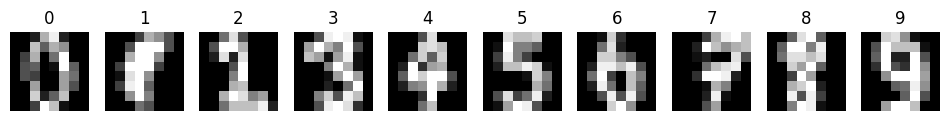

In [3]:
digits = load_digits()
X = (digits.images / 16.0).astype(np.float32)[..., None]     # (1797, 8, 8, 1)
y = digits.target
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25,
                                                  stratify=y_trval, random_state=SEED)
print({"train": X_train.shape, "validation": X_val.shape, "test": X_test.shape})

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for k, ax in enumerate(axes):
    ax.imshow(X_train[np.flatnonzero(y_train == k)[0], :, :, 0], cmap="gray")
    ax.set_title(str(k)); ax.axis("off")
plt.show()

## Train a small CNN
Architecture: **Conv(16) → Conv(32) → MaxPool → Flatten → Dense(64) → Dense(10 logits)**. Early stopping keeps the epoch with the best validation accuracy. The model outputs **logits**, so the prediction is `argmax`.

In [4]:
def build_cnn(filters=(16, 32), dense=64, name="digits_cnn"):
    layers = [keras.Input(shape=(8, 8, 1))]
    for i, f in enumerate(filters):
        layers.append(keras.layers.Conv2D(f, 3, padding="same", activation="relu", name=f"conv{i + 1}"))
    layers += [keras.layers.MaxPooling2D(name="pool"), keras.layers.Flatten(name="flatten"),
               keras.layers.Dense(dense, activation="relu", name="dense_hidden"),
               keras.layers.Dense(10, name="logits")]
    return keras.Sequential(layers, name=name)

def train_model(model, epochs=60):
    keras.utils.set_random_seed(SEED)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=10, restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs,
                        batch_size=32, verbose=0, callbacks=[stop])
    return pd.DataFrame(history.history), time.perf_counter() - start

def keras_val_accuracy(model):
    return accuracy_score(y_val, model.predict(X_val, verbose=0).argmax(1))

keras.utils.set_random_seed(SEED)
baseline = build_cnn()
history, train_s = train_model(baseline)
baseline.save(ARTIFACTS / "baseline.keras")
print(f"Training: {train_s:.1f} s | epochs run: {len(history)} | parameters: {baseline.count_params():,}")
print(f"Validation accuracy (Keras FP32): {keras_val_accuracy(baseline):.4f}")
print(f".keras file: {(ARTIFACTS / 'baseline.keras').stat().st_size / 1024:.1f} KB")
baseline.summary()

Training: 10.9 s | epochs run: 26 | parameters: 38,282
Validation accuracy (Keras FP32): 0.9917
.keras file: 483.1 KB


Model: "digits_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 8, 8, 16)       │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 8, 8, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool (MaxPooling2D)             │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 114,848 (448.63 KB)

 Trainable params: 38,282 (149.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 76,566 (299.09 KB)

# Part 2 · Quantization from scratch

Quantization stores each real number $x$ as a small integer $q$, using an **affine mapping**:

$$x \;\approx\; \text{scale} \times (q - \text{zero\_point}), \qquad q \in [-128, 127] \text{ for INT8}$$

| Choice | Meaning | Typically used for |
|---|---|---|
| **Symmetric** | `zero_point = 0` and the range is ±max\|x\| | Weights, which are roughly centred on 0 |
| **Asymmetric** | `zero_point ≠ 0` and the range is [min, max] | Activations, e.g. after ReLU everything is ≥ 0 |
| **Per-tensor** | One scale for the whole tensor | Simple and fast |
| **Per-channel** | One scale per output channel | Conv/Dense weights whose channels have very different ranges |

INT8 needs **1 byte** per value instead of 4 for FP32, so storage drops about 4×. The price is rounding error, which is at most `scale / 2` per value.

In [5]:
def quantize_symmetric(x, num_bits=8):
    qmax = 2 ** (num_bits - 1) - 1                          # 127
    scale = max(float(np.abs(x).max()) / qmax, 1e-12)
    q = np.clip(np.round(x / scale), -qmax, qmax).astype(np.int8)
    return q, scale

dense_w = baseline.get_layer("dense_hidden").get_weights()[0]
q, scale = quantize_symmetric(dense_w)
recon = q.astype(np.float32) * scale
print("Dense kernel:", dense_w.shape, f"| FP32 {dense_w.nbytes / 1024:.1f} KB -> INT8 {q.nbytes / 1024:.1f} KB (+1 scale)")
print(f"scale = {scale:.6f} | max |error| = {np.abs(dense_w - recon).max():.6f} (<= scale/2 = {scale / 2:.6f})")
print(f"mean squared error = {np.mean((dense_w - recon) ** 2):.3e}")

Dense kernel: (512, 64) | FP32 128.0 KB -> INT8 32.0 KB (+1 scale)
scale = 0.002352 | max |error| = 0.001176 (<= scale/2 = 0.001176)
mean squared error = 4.613e-07


### TODO 1 · Asymmetric and per-channel quantization
1. Implement `quantize_affine(x, num_bits=8)`, which returns `(q, scale, zero_point)` with `q` as `int8`, and `dequantize_affine(q, scale, zero_point)`. Make sure the range **includes 0**, so that 0 is represented exactly (padding and ReLU zeros depend on this).
2. Implement `quantize_per_channel(w)` for a conv kernel of shape `(kh, kw, in, out)`. It should quantize symmetrically with **one scale per output channel** (last axis) and return the dequantized tensor.
3. Fill `error_table`, a DataFrame with the mean squared error (MSE) of each case:
   - the ReLU activations of `dense_hidden` on `X_val`: symmetric vs. asymmetric;
   - the `conv2` kernel: symmetric per-tensor vs. symmetric per-channel.

   In one comment, explain each winner.

**Hints:** `qmin, qmax = -2**(b-1), 2**(b-1)-1`; `scale = (x_max - x_min) / (qmax - qmin)`; `zero_point = round(qmin - x_min / scale)`. Get the activations with `keras.Model(baseline.inputs, baseline.get_layer("dense_hidden").output).predict(X_val, verbose=0)`.

**Check:** the asserts pass. Asymmetric quantization should win clearly on the activations, and per-channel should win on the conv kernel.

In [6]:
def quantize_affine(x, num_bits=8):
    # TODO
    raise NotImplementedError("TODO 1")

def dequantize_affine(q, scale, zero_point):
    # TODO
    raise NotImplementedError("TODO 1")

def quantize_per_channel(w, num_bits=8):
    # TODO: one symmetric scale per output channel (last axis); return the dequantized tensor
    raise NotImplementedError("TODO 1")

error_table = None   # TODO

if False:  # set True after implementing
    x = np.array([-1.0, 0.0, 0.5, 3.0], dtype=np.float32)
    q, s, z = quantize_affine(x)
    assert q.dtype == np.int8 and dequantize_affine(np.array([z], np.int8), s, z)[0] == 0.0
    assert np.abs(dequantize_affine(q, s, z) - x).max() <= s / 2 + 1e-6
    display(error_table)

# Part 3 · Convert to `.tflite` and run it

`tf.lite.TFLiteConverter` turns a Keras model into a single **FlatBuffer** file (`.tflite`). The file holds the graph, the weights and, for quantized models, every scale and zero-point. The device needs only this file and the small LiteRT interpreter, not TensorFlow.

The helper below converts with one of three options. Full-integer INT8 is left for you in TODO 2. The long export log that Keras prints is hidden.

In [7]:
def to_tflite(model, mode="fp32"):
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    if mode == "dynamic":                      # INT8 weights, float activations
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
    elif mode == "float16":                    # FP16 weights
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.target_spec.supported_types = [tf.float16]
    elif mode != "fp32":
        raise ValueError(f"unknown mode {mode!r}")
    with contextlib.redirect_stdout(io.StringIO()):
        return converter.convert()

def save_bytes(data, name):
    path = ARTIFACTS / name
    path.write_bytes(data)
    return path

fp32_path = save_bytes(to_tflite(baseline, "fp32"), "digits_fp32.tflite")
print(f"{fp32_path.name}: {fp32_path.stat().st_size / 1024:.1f} KB")

digits_fp32.tflite: 153.2 KB


W0000 00:00:1793523411.224619      16 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793523411.224717      16 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793523411.233218      16 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled


## Run the interpreter
On a device, inference is always the same five steps: **load → allocate → set input → invoke → read output.** The helper runs one image at a time (batch 1), as a phone or microcontroller would.

In [8]:
def make_interpreter(path, threads=1):
    it = Interpreter(model_path=str(path), num_threads=threads)
    it.allocate_tensors()                                   # reserve memory for all tensors
    return it

def tflite_predict(path, X):
    """Logits for every image (float-input models only), one image at a time."""
    it = make_interpreter(path)
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    logits = []
    for x in X:
        it.set_tensor(inp["index"], x[None].astype(inp["dtype"]))   # add the batch axis
        it.invoke()
        logits.append(it.get_tensor(out["index"])[0].copy())
    return np.array(logits)

it = make_interpreter(fp32_path)
print("input :", {k: it.get_input_details()[0][k] for k in ["name", "shape", "dtype", "quantization"]})
print("output:", {k: it.get_output_details()[0][k] for k in ["name", "shape", "dtype", "quantization"]})

keras_logits = baseline.predict(X_val, verbose=0)
fp32_logits = tflite_predict(fp32_path, X_val)
np.testing.assert_allclose(fp32_logits, keras_logits, rtol=1e-4, atol=1e-4)
fp32_val_pred = fp32_logits.argmax(1)
print("FP32 parity with Keras passed. Validation accuracy:", round(accuracy_score(y_val, fp32_val_pred), 4))

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


input : {'name': 'serving_default_keras_tensor:0', 'shape': array([1, 8, 8, 1], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0)}
output: {'name': 'StatefulPartitionedCall_1:0', 'shape': array([ 1, 10], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0)}
FP32 parity with Keras passed. Validation accuracy: 0.9917


> **Syntax clarity: interpreter details**
>
> ```python
> inp = it.get_input_details()[0]
> inp["index"]         # integer handle used by set_tensor / get_tensor
> inp["shape"]         # e.g. [1, 8, 8, 1]: the batch axis is part of the model
> inp["dtype"]         # numpy.float32, or numpy.int8 for an integer-only model
> inp["quantization"]  # (scale, zero_point); (0.0, 0) means "not quantized"
> ```
> - `x[None]` is the same as `np.expand_dims(x, 0)`: `(8, 8, 1)` → `(1, 8, 8, 1)`.
> - `get_tensor` returns a view of the interpreter's memory. `.copy()` keeps the value safe before the next `invoke()` overwrites it.

# Part 4 · Post-training quantization (PTQ)

PTQ quantizes an already-trained model, with no retraining.

| Variant | Weights | Activations | Needs calibration data? | Typical target |
|---|---|---|---|---|
| FP32 | float32 | float32 | no | Reference |
| Dynamic range | **int8** | float (some ops quantize activations on the fly) | no | CPU, smaller download |
| Float16 | **float16** | float32 (or fp16 on GPU) | no | Mobile GPU |
| **Full integer (INT8)** | **int8** | **int8** | **yes, a representative dataset** | Edge TPU, NPUs, DSPs, microcontrollers |
| Quantization-aware training | int8 | int8 | training data | When PTQ loses too much accuracy |

Full-integer conversion must know the **range of every activation**. It runs about 100–500 typical inputs, the **representative dataset**, through the model and records the min and max of each layer. These inputs must come from the **training** data, never from validation or test.

In [9]:
dynamic_path = save_bytes(to_tflite(baseline, "dynamic"), "digits_dynamic.tflite")
float16_path = save_bytes(to_tflite(baseline, "float16"), "digits_float16.tflite")

ptq_rows = []
for name, path in [("fp32", fp32_path), ("dynamic_range", dynamic_path), ("float16", float16_path)]:
    pred = tflite_predict(path, X_val).argmax(1)
    ptq_rows.append({"variant": name, "file_KB": path.stat().st_size / 1024,
                     "val_accuracy": accuracy_score(y_val, pred),
                     "agreement_with_fp32": float(np.mean(pred == fp32_val_pred))})
display(pd.DataFrame(ptq_rows).round(4))

W0000 00:00:1793523412.508753      16 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793523412.508792      16 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
W0000 00:00:1793523413.073159      16 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793523413.073236      16 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


,variant,file_KB,val_accuracy,agreement_with_fp32
0,fp32,153.2031,0.9917,1.0
1,dynamic_range,44.7500,0.9917,1.0
2,float16,79.3398,0.9917,1.0


### TODO 2 · Full-integer INT8 conversion
1. Write `representative_dataset()`, a generator that yields the **first 200 training images**, one at a time, each as a list holding a `float32` array of shape `(1, 8, 8, 1)`.
2. Configure a converter for `baseline` with:
   - `optimizations = [tf.lite.Optimize.DEFAULT]`
   - your `representative_dataset`
   - `target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]` (fail if any op cannot be integer-only)
   - `inference_input_type = tf.int8` and `inference_output_type = tf.int8`
3. Convert it (wrap the call in `contextlib.redirect_stdout(io.StringIO())`), save it as `digits_int8.tflite` with `save_bytes`, and set `int8_path`.
4. Print the file size and the input and output `quantization` parameters. In a comment, explain why the input scale is about 1/255 and the zero-point is −128.

**Check:** the input and output dtypes are `np.int8`.

In [10]:
def representative_dataset():
    # TODO: yield [x] for the first 200 training images, x of shape (1, 8, 8, 1), float32
    raise NotImplementedError("TODO 2")

int8_path = None   # TODO: convert, save and set the path

if False:  # set True after implementing
    it8 = make_interpreter(int8_path)
    assert it8.get_input_details()[0]["dtype"] == np.int8
    assert it8.get_output_details()[0]["dtype"] == np.int8
    print("input quantization :", it8.get_input_details()[0]["quantization"])
    print("output quantization:", it8.get_output_details()[0]["quantization"])
    print(f"{int8_path.name}: {int8_path.stat().st_size / 1024:.1f} KB")
# Why scale ~ 1/255 and zero_point -128?  ->

### TODO 3 · Run an integer-only model
An INT8-input model cannot take float pixels. You must **quantize the input** with the model's own input parameters, and **dequantize the output** to get logits back:

$$q_{\text{in}} = \text{clip}\big(\text{round}(x / s_{\text{in}}) + z_{\text{in}},\,-128,\,127\big), \qquad \text{logits} = s_{\text{out}}\,(q_{\text{out}} - z_{\text{out}})$$

Implement `tflite_predict_int8(path, X)`, which returns float logits for every image. Compute the INT8 validation accuracy and the **agreement** with `fp32_val_pred`, then add the INT8 row to `ptq_rows` and display the table.

**Check:** the agreement with FP32 is ≥ 97%, and the accuracy drop is ≤ 1 percentage point.

In [11]:
def tflite_predict_int8(path, X):
    # TODO
    raise NotImplementedError("TODO 3")

# TODO: accuracy, agreement, append to ptq_rows, display

## Measure latency
`benchmark_tflite` times warm, batch-1 `invoke()` calls on one thread. It times the model only, with no preprocessing. Treat differences under about 10% as noise and repeat any comparison you rely on. The `tf.lite.experimental.Analyzer` lists the operators in a model file.

In [12]:
def benchmark_fn(fn, repeats=500, warmup=30):
    for _ in range(warmup):
        fn()
    lat = []
    for _ in range(repeats):
        t = time.perf_counter(); fn(); lat.append(time.perf_counter() - t)
    return {"p50_ms": float(np.percentile(lat, 50) * 1000), "p95_ms": float(np.percentile(lat, 95) * 1000)}

def benchmark_tflite(path, x_float):
    it = make_interpreter(path, threads=1)
    inp = it.get_input_details()[0]
    if inp["dtype"] == np.int8:
        s, z = inp["quantization"]
        x = np.clip(np.round(x_float / s) + z, -128, 127).astype(np.int8)[None]
    else:
        x = x_float[None].astype(np.float32)
    def run():
        it.set_tensor(inp["index"], x); it.invoke()
    return benchmark_fn(run)

def list_ops(path):
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        tf.lite.experimental.Analyzer.analyze(model_path=str(path))
    return [line.split("(")[0].split()[-1] for line in buf.getvalue().splitlines() if line.strip().startswith("Op#")]

print("FP32 ops:", list_ops(fp32_path))
print("FP32 latency:", {k: round(v, 4) for k, v in benchmark_tflite(fp32_path, X_val[0]).items()})
print("Keras model.__call__ latency:",
      {k: round(v, 3) for k, v in benchmark_fn(lambda: baseline(X_val[:1], training=False), repeats=100).items()})

FP32 ops: ['CONV_2D', 'CONV_2D', 'MAX_POOL_2D', 'SHAPE', 'STRIDED_SLICE', 'PACK', 'RESHAPE', 'FULLY_CONNECTED', 'FULLY_CONNECTED']
FP32 latency: {'p50_ms': 0.0188, 'p95_ms': 0.0383}
Keras model.__call__ latency: {'p50_ms': 8.283, 'p95_ms': 9.747}


### TODO 4 · Inspect and compare the four variants
1. For each `.tflite` variant (fp32, dynamic_range, float16, full_int8), count the tensors by dtype with `make_interpreter(path).get_tensor_details()`, and list the operators with `list_ops(path)`. Which variant contains `QUANTIZE` / `DEQUANTIZE` ops, and why?
2. Benchmark each variant with `benchmark_tflite(path, X_val[0])`.
3. Build `comparison`, a DataFrame with columns `variant, file_KB, val_accuracy, agreement_with_fp32, p50_ms, p95_ms, tensor_dtypes`. Plot three bar charts (size, p95, accuracy).
4. In one comment: is the smallest file also the fastest? Explain.

**Hints:** `Counter(np.dtype(t["dtype"]).name for t in ...)`. Reuse `ptq_rows` for the accuracy columns.

In [13]:
comparison = None   # TODO

# Is the smallest file also the fastest?  ->

# Part 5 · Edge deployment

What actually ships to the device:

1. **The model file** (`.tflite`), plus its checksum so the app can verify the download.
2. **A preprocessing contract.** The device must transform the input *exactly* as in training (here: divide raw 0–16 pixels by 16) and know the input dtype and quantization parameters, the labels, and so on. A metadata JSON file is the simplest way to carry this.
3. **A small runtime.** The device does not run TensorFlow.

| Target | Runtime | Notes |
|---|---|---|
| Android / iOS | LiteRT (Kotlin/Java, Swift, C++) | GPU and NPU delegates; FP16/INT8 |
| Raspberry Pi, Jetson, Linux boards | `ai-edge-litert` Python wheel or C++ | The same API you used in this notebook |
| Coral Edge TPU, phone NPUs | LiteRT + vendor delegate | Requires a **full-integer** model |
| Microcontrollers (Arduino, ESP32, Cortex-M) | LiteRT for Microcontrollers (C++) | No OS and no file system. The model is compiled in as a C array. RAM is measured in KB |

In [14]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def write_meta(model_path, val_accuracy, name):
    inp = make_interpreter(model_path).get_input_details()[0]
    meta = {"model_file": Path(model_path).name, "sha256": sha256(model_path),
            "input_shape": [int(v) for v in inp["shape"]], "input_dtype": np.dtype(inp["dtype"]).name,
            "input_scale": float(inp["quantization"][0]), "input_zero_point": int(inp["quantization"][1]),
            "preprocessing": "raw 8x8 pixels (0-16) / pixel_divisor, then add batch and channel axes",
            "pixel_divisor": 16.0, "labels": [str(d) for d in range(10)],
            "val_accuracy": round(float(val_accuracy), 4), "created": time.strftime("%Y-%m-%d %H:%M")}
    path = ARTIFACTS / name
    path.write_text(json.dumps(meta, indent=2))
    return path

meta_fp32_path = write_meta(fp32_path, accuracy_score(y_val, fp32_val_pred), "meta_fp32.json")
print(meta_fp32_path.read_text())

# Raw pixels (0-16) of 20 validation images: what a device camera/sensor pipeline would hand over.
edge_images = np.round(X_val[:20, :, :, 0] * 16).astype(np.uint8)
np.save(ARTIFACTS / "edge_images.npy", edge_images)

{
  "model_file": "digits_fp32.tflite",
  "sha256": "015bc1fbb3f76152aff122682c83ad2583de2917722fafb0b6846a68c21590fc",
  "input_shape": [
    1,
    8,
    8,
    1
  ],
  "input_dtype": "float32",
  "input_scale": 0.0,
  "input_zero_point": 0,
  "preprocessing": "raw 8x8 pixels (0-16) / pixel_divisor, then add batch and channel axes",
  "pixel_divisor": 16.0,
  "labels": [
    "0",
    "1",
    "2",
    "3",
    "4",
    "5",
    "6",
    "7",
    "8",
    "9"
  ],
  "val_accuracy": 0.9917,
  "created": "2026-11-01 08:56"
}


## A standalone edge program
The next cell writes `edge_infer.py`. It imports only **NumPy and the LiteRT interpreter**, never TensorFlow, so it would run unchanged on a Raspberry Pi. It reads the metadata, applies the preprocessing contract, quantizes and dequantizes if the model is INT8, and prints one JSON line: predictions, model-load time, warm latency and the process's peak memory.

The notebook then runs it in a **fresh process**, so the memory reading covers only the edge program and not this notebook.

In [15]:
EDGE_SOURCE = r"""
import time
START = time.perf_counter()
import argparse, json, sys
from pathlib import Path
import numpy as np
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:                      # older name of the same lightweight runtime
    from tflite_runtime.interpreter import Interpreter
def peak_rss_mib():
    if sys.platform.startswith("linux"):              # high-water mark of THIS process
        for line in open("/proc/self/status"):
            if line.startswith("VmHWM:"):
                return int(line.split()[1]) / 1024
    try:
        import resource
        peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        return peak / 2**20 if sys.platform == "darwin" else peak / 1024
    except ImportError:                               # Windows: not available
        return None

p = argparse.ArgumentParser()
p.add_argument("--model", required=True)
p.add_argument("--meta", required=True)
p.add_argument("--images", required=True)
p.add_argument("--repeats", type=int, default=300)
a = p.parse_args()

meta = json.loads(Path(a.meta).read_text())
raw = np.load(a.images).astype(np.float32)                 # (N, 8, 8) raw pixels 0..16
x = (raw / meta["pixel_divisor"])[..., None]               # preprocessing contract

t = time.perf_counter()
it = Interpreter(model_path=a.model, num_threads=1)
it.allocate_tensors()
load_ms = (time.perf_counter() - t) * 1000
inp, out = it.get_input_details()[0], it.get_output_details()[0]

def predict(img):
    if inp["dtype"] == np.int8:
        s, z = inp["quantization"]
        img = np.clip(np.round(img / s) + z, -128, 127).astype(np.int8)
    it.set_tensor(inp["index"], img[None].astype(inp["dtype"]))
    it.invoke()
    y = it.get_tensor(out["index"])[0]
    if out["dtype"] == np.int8:
        s, z = out["quantization"]
        y = s * (y.astype(np.float32) - z)
    return int(np.argmax(y))

preds = [predict(img) for img in x]
lat = []
for _ in range(a.repeats):
    t = time.perf_counter(); predict(x[0]); lat.append(time.perf_counter() - t)

print(json.dumps({"model": Path(a.model).name, "predictions": preds,
                  "labels": [meta["labels"][i] for i in preds],
                  "startup_s": time.perf_counter() - START - sum(lat), "model_load_ms": load_ms,
                  "p50_ms": float(np.percentile(lat, 50) * 1000), "p95_ms": float(np.percentile(lat, 95) * 1000),
                  "peak_rss_MiB": peak_rss_mib()}))
"""
(ARTIFACTS / "edge_infer.py").write_text(EDGE_SOURCE.strip() + "\n")

def run_edge(model_path, meta_path):
    cmd = [sys.executable, str(ARTIFACTS / "edge_infer.py"), "--model", str(model_path),
           "--meta", str(meta_path), "--images", str(ARTIFACTS / "edge_images.npy")]
    done = subprocess.run(cmd, capture_output=True, text=True, timeout=120, check=True)
    return json.loads(done.stdout.strip().splitlines()[-1])

edge_fp32 = run_edge(fp32_path, meta_fp32_path)
print({k: v for k, v in edge_fp32.items() if k != "labels"})
assert edge_fp32["predictions"] == fp32_val_pred[:20].tolist(), "edge program disagrees with the notebook!"
print("Edge program matches the notebook predictions on 20 images.")

CalledProcessError: Command '['/usr/bin/python3', 'lab9_artifacts/edge_infer.py', '--model', 'lab9_artifacts/digits_fp32.tflite', '--meta', 'lab9_artifacts/meta_fp32.json', '--images', 'lab9_artifacts/edge_images.npy']' returned non-zero exit status 1.

## Why not just ship TensorFlow?
Compare how long it takes, and how much memory it needs, merely to **import** each runtime in a fresh process.

In [ ]:
PROBE = r"""
import time, sys, json, importlib
t = time.perf_counter()
importlib.import_module(sys.argv[1])
dt = time.perf_counter() - t
def peak_rss_mib():
    if sys.platform.startswith("linux"):              # high-water mark of THIS process
        for line in open("/proc/self/status"):
            if line.startswith("VmHWM:"):
                return int(line.split()[1]) / 1024
    try:
        import resource
        peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        return peak / 2**20 if sys.platform == "darwin" else peak / 1024
    except ImportError:                               # Windows: not available
        return None
print(json.dumps({"module": sys.argv[1], "import_s": dt, "peak_rss_MiB": peak_rss_mib()}))
"""
(ARTIFACTS / "import_probe.py").write_text(PROBE.strip() + "\n")
probe_rows = []
for module in ["numpy", "ai_edge_litert.interpreter", "tensorflow"]:
    env = {**os.environ, "TF_CPP_MIN_LOG_LEVEL": "2"}
    try:
        done = subprocess.run([sys.executable, str(ARTIFACTS / "import_probe.py"), module],
                              capture_output=True, text=True, timeout=180, check=True, env=env)
        probe_rows.append(json.loads(done.stdout.strip().splitlines()[-1]))
    except subprocess.CalledProcessError:
        probe_rows.append({"module": module, "import_s": None, "peak_rss_MiB": None})
display(pd.DataFrame(probe_rows).round(2))

### TODO 5 · Package and validate the INT8 model for the edge
1. Write `meta_int8.json` with `write_meta` for the INT8 model, and print it. Check that it carries the input scale and zero-point.
2. Run `run_edge(int8_path, meta_int8_path)`. Assert that its predictions are **identical** to `int8_val_pred[:20]` from your notebook.
3. Build `edge_report`, a DataFrame comparing the fp32 and int8 edge runs: file KB, model-load ms, p50/p95 ms, peak RSS MiB, and whether the predictions match the notebook.
4. In 2–3 sentences: does a 4× smaller model file give a 4× smaller process? Use your import-probe numbers to say what dominates memory on the device.

**Check:** both edge runs match the notebook predictions exactly.

In [ ]:
meta_int8_path = None   # TODO
edge_report = None      # TODO

answer_todo5 = """
...
"""

## Microcontrollers: the model becomes C source code
A microcontroller has no file system. The `.tflite` bytes are compiled into the firmware as a C array, which is what `xxd -i model.tflite` produces. At run time, LiteRT Micro needs one extra block of RAM, the **tensor arena**, which holds the activations, inputs and outputs. The model weights stay in **flash**.

### TODO 6 · Export the INT8 model as a C header
1. Implement `to_c_array(model_bytes, var_name="g_digits_model")`. It returns the text of a C header containing:
   - a comment with the size in bytes;
   - `alignas(16) const unsigned char g_digits_model[] = { 0x.., 0x.., ... };`, with 12 bytes per line;
   - `const unsigned int g_digits_model_len = <N>;`
2. Write it to `lab13_artifacts/digits_model.h`, print the first 4 lines and the last 2, and **verify** the result by parsing every `0x..` value back into bytes: they must equal the `.tflite` bytes exactly.
3. Answer in `answer_todo6`: (a) Why do microcontroller deployments need a **full-integer** model? (b) Which part of memory holds the weights, and which holds the tensor arena?

**Hints:** `", ".join(f"0x{b:02x}" for b in chunk)`; `re.findall(r"0x([0-9a-f]{2})", text)`; `bytes(int(h, 16) for h in ...)`.

In [ ]:
def to_c_array(model_bytes, var_name="g_digits_model"):
    # TODO
    raise NotImplementedError("TODO 6")

# TODO: write the header, print head/tail, verify the round trip

answer_todo6 = """
(a) ...
(b) ...
"""

# Part 6 · Choose a model and evaluate once

### TODO 7 · Choose the deployment variant
Using **validation results only** (`comparison` and `edge_report`), choose the variant you would ship to a Raspberry-Pi-class device and to a microcontroller. Freeze that choice in `final_report`. Then evaluate your Raspberry Pi choice **once** on `X_test, y_test`: report the test accuracy and plot the confusion matrix with `ConfusionMatrixDisplay`. Save `final_report` as JSON.

**Hints:** `tflite_predict` / `tflite_predict_int8` followed by `argmax(1)`; `confusion_matrix(y_test, pred)`.

In [ ]:
final_report = {
    "chosen_for_raspberry_pi": "",       # TODO: freeze before touching test data
    "chosen_for_microcontroller": "",    # TODO
    "reasoning": "",                     # TODO: size / accuracy / latency / hardware
    "test_accuracy": None,               # TODO: one final evaluation
}
# TODO: one test evaluation + confusion matrix + save JSON

# Part 7 · Research case study: EEGNet on motor-imagery EEG

In the lecture's **Case 2** (slides 39–40) we measured what INT8 costs for EEG models on **motor imagery (MI)**: a person imagines moving the left or the right hand, and a classifier reads the intention from the EEG. EEGNet lost 1.04 accuracy points at INT8 in that study. Here you repeat the measurement with the tools of this lab.

**Dataset.** [PhysioNet EEG Motor Movement/Imagery](https://physionet.org/content/eegmmidb/1.0.0/) (Schalk et al., 2004): open data, 64-channel EEG at 160 Hz. We use runs 4, 8 and 12 (imagine opening and closing the **left** or the **right fist**), which gives a two-class MI problem. The cells below prepare it for you:

| Step | Choice |
|---|---|
| Channels | 20 over the motor cortex (`FC5 … CP6`) |
| Filter and rate | band-pass 4–38 Hz, resampled to 128 Hz |
| Window | the first 2 s after the cue = **256 samples**, so the input is `(20, 256, 1)` (compare `1 × C × 256` on slide 39) |
| Scaling | z-score per trial and channel |
| Split | **by subject**: 60% train / 20% validation / 20% test subjects. No person appears in two splits, because a deployed device meets new people |

Needs `mne` and, the first time, an internet connection. The downloaded files and the prepared arrays are cached in `lab13_artifacts/`. **EEGNet** is the compact network of Lawhern et al., 2018 ([arXiv:1611.08024](https://arxiv.org/abs/1611.08024)).

In [ ]:
INSTALL_MNE = False
if INSTALL_MNE:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "mne"])      # then restart the kernel

try:
    import mne
    from mne.datasets import eegbci
except ImportError as err:
    raise ImportError("Part 7 needs `mne`: set INSTALL_MNE = True, run this cell, then restart the kernel.") from err
mne.set_log_level("ERROR")

MI_CHANNELS = ["FC5", "FC3", "FC1", "FC2", "FC4", "FC6", "C5", "C3", "C1", "Cz", "C2", "C4", "C6",
               "CP5", "CP3", "CP1", "CPz", "CP2", "CP4", "CP6"]               # 20 channels over the motor cortex
MI_SFREQ, MI_T = 128, 256                         # 2 s at 128 Hz: the 1 x C x 256 input of slide 39
MI_SUBJECTS = list(range(1, 31))                  # PhysioNet subjects S001-S030
MI_DIR, MI_CACHE = ARTIFACTS / "eegmmidb", ARTIFACTS / "mi_physionet.npz"

def load_mi_subject(subject):
    """Left- vs right-fist imagery trials of one subject: X (n, 20, 256), y (n,) with 0 = left, 1 = right."""
    X, y = [], []
    for edf in eegbci.load_data(subject, runs=[4, 8, 12], path=str(MI_DIR)):    # downloads once, then reuses
        raw = mne.io.read_raw_edf(edf, preload=True, verbose=False)
        eegbci.standardize(raw)                                                 # "Fc5." -> "FC5"
        raw.pick(MI_CHANNELS)
        raw.filter(4.0, 38.0, fir_design="firwin", verbose=False)
        raw.resample(MI_SFREQ)
        events, _ = mne.events_from_annotations(raw, event_id={"T1": 1, "T2": 2})
        epochs = mne.Epochs(raw, events, {"left": 1, "right": 2}, tmin=0.0, tmax=(MI_T - 1) / MI_SFREQ,
                            baseline=None, preload=True, verbose=False)
        X.append(epochs.get_data()); y.append(epochs.events[:, 2] - 1)
    return np.concatenate(X), np.concatenate(y)

if MI_CACHE.exists():
    cached = np.load(MI_CACHE)
    X_mi, y_mi, subject_mi = cached["X"], cached["y"], cached["subject"]
else:
    parts = [(*load_mi_subject(s), s) for s in MI_SUBJECTS]
    X_mi = np.concatenate([p[0] for p in parts]).astype(np.float64)
    y_mi = np.concatenate([p[1] for p in parts])
    subject_mi = np.concatenate([np.full(len(p[1]), p[2]) for p in parts])
    X_mi = ((X_mi - X_mi.mean(-1, keepdims=True)) / (X_mi.std(-1, keepdims=True) + 1e-12)).astype(np.float32)[..., None]
    np.savez_compressed(MI_CACHE, X=X_mi, y=y_mi, subject=subject_mi)

def mi_subset(subjects):
    keep = np.isin(subject_mi, subjects)
    return X_mi[keep], y_mi[keep]

X_mi_train, y_mi_train = mi_subset(MI_SUBJECTS[:18])      # 18 training subjects
X_mi_val, y_mi_val = mi_subset(MI_SUBJECTS[18:24])        # 6 validation subjects
X_mi_test, y_mi_test = mi_subset(MI_SUBJECTS[24:])        # 6 test subjects: touch once, at the end
for name, (xs, ys) in {"train": (X_mi_train, y_mi_train), "validation": (X_mi_val, y_mi_val), "test": (X_mi_test, y_mi_test)}.items():
    print(f"{name:10s} {xs.shape} | class counts (left, right): {np.bincount(ys).tolist()}")

## The EEGNet model
`build_eegnet` is a simplified **EEGNet-8,2**: a temporal convolution (frequency filters), a depthwise convolution across all 20 channels (spatial filters), a separable convolution, and a linear classifier that outputs **logits**. The max-norm constraints of the original paper are left out. Its activation is a parameter, because the choice matters for integer-only hardware (see the last question of TODO 8).

In [ ]:
def build_eegnet(n_ch=20, n_t=MI_T, n_classes=2, F1=8, D=2, F2=16, kern=64, dropout=0.5, activation="elu", name="eegnet"):
    L = keras.layers
    return keras.Sequential([
        keras.Input(shape=(n_ch, n_t, 1)),
        L.Conv2D(F1, (1, kern), padding="same", use_bias=False, name="temporal_conv"),
        L.BatchNormalization(),
        L.DepthwiseConv2D((n_ch, 1), depth_multiplier=D, use_bias=False, name="spatial_depthwise"),
        L.BatchNormalization(), L.Activation(activation),
        L.AveragePooling2D((1, 4)), L.Dropout(dropout),
        L.SeparableConv2D(F2, (1, 16), padding="same", use_bias=False, name="separable"),
        L.BatchNormalization(), L.Activation(activation),
        L.AveragePooling2D((1, 8)), L.Dropout(dropout),
        L.Flatten(), L.Dense(n_classes, name="logits"),
    ], name=name)

print("EEGNet parameters:", f"{build_eegnet().count_params():,}", "(your count will differ from the lecture's EEGNet with other settings)")

### TODO 8 · EEGNet on motor-imagery EEG: what does INT8 cost?

> **Train EEGNet on an open motor-imagery dataset, then export float32, dynamic-range, float16 and full-int8 `.tflite` models. Report size, latency and accuracy in one table and compare your INT8 drop with the case studies.**

1. **Train.** Build `eegnet = build_eegnet()` and train it on `X_mi_train`, with early stopping on the **validation** accuracy (the recipe of `train_model`, but on the MI arrays). Print the parameter count and the validation accuracy.
2. **Export four files** with `save_bytes`: `eegnet_fp32.tflite`, `eegnet_dynamic.tflite`, `eegnet_float16.tflite` (use `to_tflite`) and `eegnet_int8.tflite`. For the last one, implement `to_tflite_int8(model, X_calib, n=200)` by generalising TODO 2: the representative dataset is the first 200 **training** trials, each a `float32` array of shape `(1, 20, 256, 1)`, with int8 input and output. Store the paths in `eegnet_paths` with the keys `fp32`, `dynamic_range`, `float16`, `full_int8`.
3. **One table.** Build `eegnet_table` with one row per variant and the columns `variant, file_KB, val_accuracy, test_accuracy, agreement_with_fp32, p50_ms, p95_ms`. Use `tflite_predict` / `tflite_predict_int8` (generalise yours from TODO 3 if it hard-codes the digit shape) and `benchmark_tflite(path, X_mi_val[0])`. All four variants are reported, so no choice is made from the test subjects: evaluate each variant on them once.
4. **Compare with the case studies.** Compute `int8_drop_pp` = (FP32 test accuracy − INT8 test accuracy) × 100. Build `drop_comparison`: a copy of `CASE_STUDY_MI` (lecture slide 40) with one extra row for your model, named `"EEGNet (yours)"`, with the same columns.
5. **Explain** in `answer_todo8`:
   - (a) Where does your drop fall among DeepConvNet, EEGNet, ShallowConvNet, TSception and SwitchBraidNet? How many test trials equal one accuracy point? Is your drop signal or noise, and what does the **agreement** column add?
   - (b) Is your dynamic-range file smaller than FP32? Count the tensors by dtype as in TODO 4 to see why.
   - (c) Run `list_ops` on the INT8 file. Do `QUANTIZE` or `DEQUANTIZE` operators appear, and around which operator? What would that mean on an integer-only target (see "Common mistakes" in the lecture)? Try `build_eegnet(activation="relu")` and compare.

**Hints:** `keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=15, restore_best_weights=True)`; `Adam(1e-3)`; `SparseCategoricalCrossentropy(from_logits=True)`; `batch_size=32`. The case-study rows come from a different dataset (OpenBMI, 54 subjects), so compare the **size of the drop**, not the absolute accuracy.

**Check:** the four files exist, the INT8 input dtype is `np.int8`, and the FP32 `.tflite` logits match Keras.

In [ ]:
# Case-study numbers from lecture slide 40 (OpenBMI motor imagery; accuracy in %, drop in percentage points).
CASE_STUDY_MI = pd.DataFrame([
    {"model": "DeepConvNet",    "params": 87552, "int8_KB": 85.50, "mi_fp32": 68.57, "mi_int8": 68.39, "drop_pp": 0.18},
    {"model": "EEGNet",         "params": 2292,  "int8_KB": 2.24,  "mi_fp32": 69.08, "mi_int8": 68.04, "drop_pp": 1.04},
    {"model": "ShallowConvNet", "params": 17962, "int8_KB": 17.54, "mi_fp32": 68.29, "mi_int8": 63.79, "drop_pp": 4.50},
    {"model": "TSception",      "params": 81617, "int8_KB": 79.70, "mi_fp32": 65.73, "mi_int8": 65.48, "drop_pp": 0.25},
    {"model": "SwitchBraidNet", "params": 3106,  "int8_KB": 3.03,  "mi_fp32": 69.33, "mi_int8": 69.12, "drop_pp": 0.21},
])

def to_tflite_int8(model, X_calib, n=200):
    # TODO: generalise TODO 2: representative dataset from X_calib[:n], int8 input and output
    raise NotImplementedError("TODO 8")

eegnet = None            # TODO: build_eegnet(), train with early stopping on the validation set
eegnet_paths = {}        # TODO: {"fp32": ..., "dynamic_range": ..., "float16": ..., "full_int8": ...}
eegnet_table = None      # TODO: variant, file_KB, val_accuracy, test_accuracy, agreement_with_fp32, p50_ms, p95_ms
int8_drop_pp = None      # TODO: (FP32 test accuracy - INT8 test accuracy) * 100
drop_comparison = None   # TODO: CASE_STUDY_MI plus your "EEGNet (yours)" row

answer_todo8 = """
(a) ...
(b) ...
(c) ...
"""

if False:  # set True after implementing
    assert set(eegnet_table["variant"]) == {"fp32", "dynamic_range", "float16", "full_int8"}
    assert all(Path(p).exists() for p in eegnet_paths.values())
    it8 = make_interpreter(eegnet_paths["full_int8"])
    assert it8.get_input_details()[0]["dtype"] == np.int8
    np.testing.assert_allclose(tflite_predict(eegnet_paths["fp32"], X_mi_val), eegnet.predict(X_mi_val, verbose=0), rtol=1e-3, atol=1e-3)
    display(eegnet_table.round(4))
    print(f"EEGNet parameters: {eegnet.count_params():,} | test trials: {len(y_mi_test)} (one trial = {100 / len(y_mi_test):.2f} points)")
    print(f"INT8 drop on the test subjects: {int8_drop_pp:.2f} percentage points")
    display(drop_comparison.round(2))
    print("INT8 ops:", list_ops(eegnet_paths["full_int8"]))

## Submit your work
Submit the notebook with:

- All eight TODOs completed, with outputs from your run (keep the `if False` checks switched to `True`).
- The PTQ comparison table and plots, the edge report, the C header round-trip check and your final report.
- The EEGNet table and your INT8-drop comparison with the case studies (TODO 8).
- The final challenge below.

Keep **file size**, **process memory** and **latency** clearly separate. Choose with validation data, and test once.

## Read more
[LiteRT overview](https://ai.google.dev/edge/litert) · [Post-training quantization](https://ai.google.dev/edge/litert/models/post_training_quantization) · [LiteRT for Microcontrollers](https://ai.google.dev/edge/litert/microcontrollers/overview) · [Migrating from tf.lite.Interpreter](https://ai.google.dev/edge/litert/migration) · [Quantization paper: Jacob et al., 2018](https://arxiv.org/abs/1712.05877)

## Complete the lab challenge
### Fit the 8 KB edge budget
Your INT8 baseline is about 45 KB. The target microcontroller has only **8 KB** of flash left for the model, more than 5× less.

**Tasks**

1. Design and train **at least three** smaller architectures. First find out **where the bytes are** (`model.summary()`): ideas include fewer filters before `Flatten`, a smaller or no hidden dense layer, `GlobalAveragePooling2D` and `SeparableConv2D`. Use the same splits and seed, and record the parameter count and training time of each.
2. Convert each one to **full INT8** (int8 input and output) with a representative dataset from the **training** set.
3. Make a table with params, `.tflite` KB, validation accuracy, agreement with that model's own FP32 version, and p50/p95 latency. Then make a **Pareto plot** of validation accuracy against file size, with a vertical line at 8 KB.
4. Choose a model with validation only. Write its metadata and run it with `edge_infer.py` in a fresh process, showing that the predictions match the notebook. Report the peak RSS.
5. Export it as a C header and verify the round trip.
6. Evaluate the chosen model **once** on the test set and show its confusion matrix.
7. *Optional:* package `edge_infer.py`, your model and metadata in a Docker image (`python:3.12-slim` + `numpy` + `ai-edge-litert`). Run it with `--cpus=0.5 --memory=64m --memory-swap=64m` and record whether it ran successfully.

**Pass criteria:** INT8 `.tflite` **≤ 8 KB**, validation accuracy **≥ 96%**, edge-program predictions identical to the notebook, and an honest test-set result.

In [ ]:
# INDEPENDENT CHALLENGE WORKSPACE: implement your own solution below.
challenge_rows = []
challenge_summary = {
    "architectures_tried": "",
    "selected_model": "",
    "int8_file_KB": None,
    "validation_accuracy": None,
    "edge_predictions_match": None,
    "peak_rss_MiB": None,
    "test_accuracy": None,
    "tradeoff_note": "",
}
# TODO: train, convert, compare, Pareto plot, edge run, C header, one test evaluation.